**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [ ]:
! pip install lightning torchmetrics torchinfo

3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# Generating digit images with a variational autoencoder


### Question 1

Create the *datasets* and then the *dataloaders* for the training and validation sets of the MNIST dataset, implemented in the [`torchvision.datasets.MNIST()`](https://pytorch.org/vision/main/generated/torchvision.datasets.MNIST.html) class, using the following information:

* For the *datasets*, don't forget to transform the raw inputs, which are PIL images of integers between $0$ and $255$, into 32-bit floating-point tensors between $0.0$ and $1.0$.

* For the *dataloaders*, we will use batches of size $64$. Samples should be shuffled on the training set, but not on the validation set.

In [3]:
import torch
from torch.utils.data import DataLoader
from torchvision.datasets import MNIST
from torchvision.transforms import v2


dataset_train = MNIST(
    "data", train=True, download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)
dataset_val = MNIST(
    "data", train=False, download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)

batch_size = 64
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=batch_size, shuffle=False)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9.91M/9.91M [00:01<00:00, 5.41MB/s]
100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 28.9k/28.9k [00:00<00:00, 168kB/s]
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1.65M/1.65M [00:00<00:00, 2.72MB/s]
100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 4.54k/4.54k [00:00<00:00, 4.06MB/s]


### Question 2

Determine the image size. We will assume that all images have the same size.

In [4]:
input_size = tuple(dataset_train[0][0].size())
print(f"Image size = {input_size}")

Image size = (1, 28, 28)


Let's visualize a few samples from the training set:

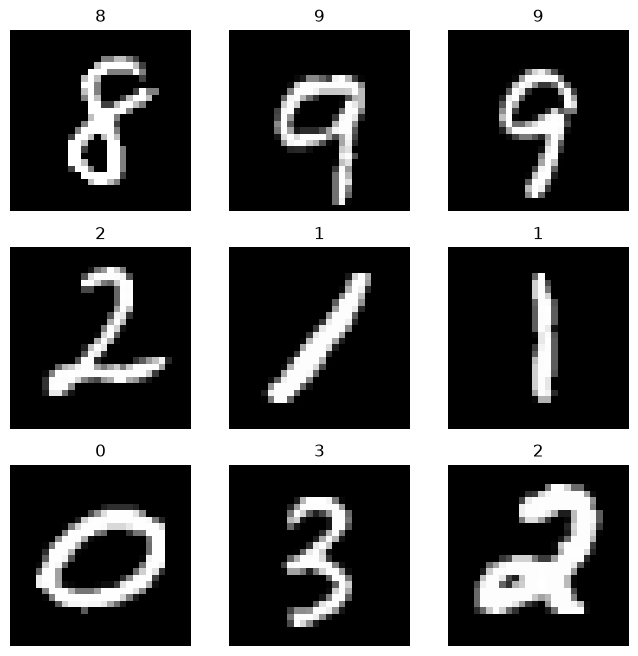

In [5]:
import matplotlib.pyplot as plt


figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(dataset_train), size=(1,)).item()
    img, label = dataset_train[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(f"{label}")
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

## Model architecture and training

A variational autoencoder is a generative variant of the autoencoder.

### Architecture

The image below summarizes the architecture you will implement:

[<img src="https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/vae_computation_graph.png" width="650"/>](https://raw.githubusercontent.com/johannfaouzi/smart-data-deep-learning/main/figures/vae_computation_graph.png)

A variational autoencoder is composed of two elements: the encoder (denoted by $q$ in the image) and the decoder (denoted by $p$ in the image).

The input of the encoder, denoted by $x$, is a digit image.
The output of the encoder consists of two vectors: the mean $\mu$ and the log-variance $\log(\sigma^2)$ of a multivariate Gaussian distribution $\mathcal{N}(\mu, \sigma^2)$.
We assume that the covariance matrix is diagonal, which is why it is characterized by a simple vector (corresponding to the diagonal of this matrix).

The input of the decoder is a random variable generated according to the distribution $\mathcal{N}(\mu, \sigma^2)$.
To obtain such a variable, we first generate a random vector ${z}$ according to the distribution $\mathcal{N}(0, I)$, then apply the affine transformation $\mu + \sigma \odot z$, which follows the distribution $\mathcal{N}(\mu, \sigma^2)$.

The dimension of the latent space, denoted by `latent_dim`, will be a hyperparameter of our class.
We will use the default value, i.e., `latent_dim = 8`.

For the encoder, you will implement the following sequential architecture:

* Flatten layer
* Linear layer with $512$ output variables
* ReLU activation function
* Linear layer with $256$ output variables
* ReLU activation function
* Linear layer with $2 \times$ `latent_dim` output variables

The output of the encoder is a one-dimensional tensor, i.e., a vector, of size $2 \times$ `latent_dim` since it contains both the tensor of size `latent_dim` for the mean $\mu$ and the tensor of size `latent_dim` for the log-variance $\log(\sigma^2)$.

For the decoder, you will implement the following sequential architecture:

* Linear layer with $256$ output variables
* ReLU activation function
* Linear layer with $512$ output variables
* ReLU activation function
* Linear layer with $784$ output variables
* Sigmoid activation function
* Unflatten layer

The role of the last layer is to transform the vector into an image, i.e., a three-dimensional tensor.

Here are the links to the documentation of the relevant tools for building these two architectures:
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html),
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html),
[`torch.nn.ReLU()`](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html),
[`torch.nn.Sigmoid()`](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html), and
[`torch.nn.Unflatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Unflatten.html).

To generate independent random variables according to the standard normal distribution, you can use the [`torch.randn()`](https://pytorch.org/docs/stable/generated/torch.randn.html) function, or the even more convenient [`torch.randn_like()`](https://pytorch.org/docs/stable/generated/torch.randn_like.html) function.

### Loss function

The loss function $J$, composed of two different terms, is defined by the following equation:
$$
    J(\tilde{x}, x) = \text{BCE}(\tilde{x}, x) + \lambda \times KL
$$
where:
* $x$ is the original image (input of the encoder) and $\tilde{x}$ is the reconstructed image (output of the decoder),
$\text{BCE}(\tilde{x}, x)$ is the cross-entropy between $\tilde{x}$ and $x$: it corresponds to the **reconstruction error**.
* $KL$ is the [Kullback-Leibler divergence](https://en.wikipedia.org/wiki/Kullback%E2%80%93Leibler_divergence) between the used distribution $\mathcal{N}(\mu, \sigma^2)$ and the target distribution $\mathcal{N}(0, I)$: it encourages the latent space to follow an isotropic Gaussian distribution. Its formula is as follows:
$$
    KL = - \frac{1}{2} \sum_{i=1}^p \left( 1 + \log(\sigma_i^2) - \mu_i^2 - \sigma_i^2 \right)
$$
where $\mu = (\mu_1, \ldots, \mu_p)$, $\sigma = (\sigma_1, \ldots, \sigma_p)$, and $p$ is the dimension of the latent space.
The Kullback-Leibler divergence is computed for each image and then averaged over the images of the batch (just like the binary cross-entropy, which is averaged over all the pixels of the batch), so that the loss function does not depend on the batch size.
* $\lambda$ is the weighting factor for the Kullback-Leibler divergence relative to the binary cross-entropy.

Here is the link to the documentation of [`torch.nn.BCELoss()`](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html).
For the Kullback-Leibler divergence, you can use the functions
[`torch.sum()`](https://pytorch.org/docs/stable/generated/torch.sum.html),
[`torch.exp()`](https://pytorch.org/docs/stable/generated/torch.exp.html), and
[`torch.pow()`](https://pytorch.org/docs/stable/generated/torch.pow.html).

### Evaluation

To compare the reconstructed images with the original images, we will use the [*structural similarity index measure*](https://en.wikipedia.org/wiki/Structural_similarity_index_measure).
More explanations about this metric will be provided in a future notebook.
All you need to know for now is that its values range between $0$ (worst) and $1$ (best).

### Question 3

Complete the `__init__()`, `encode()`, `reparametrize()`, `decode()`, `forward()`, and `loss_function()` methods of the `VAE()` class using the information provided above.

In [6]:
import lightning as L
from torchmetrics.image import StructuralSimilarityIndexMeasure


class VAE(L.LightningModule):
    """Class defining the variational autoencoder."""
    def __init__(self, latent_dim=8):
        super().__init__()
        
        if not (isinstance(latent_dim, int) and latent_dim > 0):
            raise ValueError("The latent dimension must be a positive integer.")
        self.latent_dim = latent_dim

        ### BEGIN TODO ###
        # Instantiate the encoder
        self.encoder = torch.nn.Sequential(
            torch.nn.Flatten(start_dim=-3),
            torch.nn.Linear(784, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 256),
            torch.nn.ReLU(),
            torch.nn.Linear(256, 2 * latent_dim)
        )
        
        # Instantiate the decoder
        self.decoder = torch.nn.Sequential(
            torch.nn.Linear(latent_dim, 256),
            torch.nn.ReLU(),
            torch.nn.Linear(256, 512),
            torch.nn.ReLU(),
            torch.nn.Linear(512, 784),
            torch.nn.Sigmoid(),
            torch.nn.Unflatten(-1, (1, 28, 28))
        )
        
        # Instantiate the loss
        self.bce_loss = torch.nn.BCELoss()

        # Weighting factor of the KL divergence
        self.lambda_kld = 6.4e-3
    
        # Instantiate the metrics
        self.metric_train = StructuralSimilarityIndexMeasure()
        self.metric_val = StructuralSimilarityIndexMeasure()
        #### END TODO ####

    def encode(self, x):
        """Performs the forward pass of the encoder.
        
        Parameters
        ----------
        x : Tensor, shape = [batch_size, 1, 28, 28]
            Batch of real images.
        
        Returns
        -------
        mu : Tensor, shape = [batch_size, latent_dim]
            Means of the Gaussian distributions.
            
        log_var : Tensor, shape = [batch_size, latent_dim]
            Log-variances of the Gaussian distributions.
        """
        ### BEGIN TODO ###
        mu_log_var = self.encoder(x)
        mu = mu_log_var[..., :self.latent_dim]
        log_var = mu_log_var[..., self.latent_dim:]
        #### END TODO ####
        return mu, log_var

    def reparametrize(self, mu, log_var):
        """Reparametrization of the model.
        
        Random variables `z` are independently drawn from the standard Gaussian
        distribution N(0, 1). Using the means and the log-variances, random
        variables from the N(mu, var) are drawn using the linear transformation
        mu + z * std.
        
        Parameters
        ----------
        mu : Tensor, shape = [batch_size, latent_dim]
            Means of the Gaussian distributions.
            
        log_var : Tensor, shape = [batch_size, latent_dim]
            Log-variances of the Gaussian distributions.
        """
        ### BEGIN TODO ###
        z_standard = torch.randn_like(mu, device=self.device)
        z = mu + torch.exp(log_var / 2) * z_standard
        #### END TODO ####
        return z
    
    def decode(self, z):
        """Performs the forward pass of the decoder.
        
        Parameters
        ----------
        z : Tensor, shape = [batch_size, latent_dim]
            Random variables drawn from the N(mu, var) distribution.
        
        Returns
        -------
        x_reconstructed : Tensor, shape = [batch_size, 1, 28, 28]
            Reconstructed images.
        """
        ### BEGIN TODO ###
        x_reconstructed = self.decoder(z)
        #### END TODO ####
        return x_reconstructed

    def forward(self, x):
        """Performs the forward pass.
        
        Parameters
        ----------
        x : Tensor, shape = [batch_size, 1, 28, 28]
            Batch of real images.
        
        Returns
        -------
        x_reconstructed : Tensor, shape = [batch_size, 1, 28, 28]
            Batch of reconstructed images.
        
        mu : Tensor, shape = [batch_size, latent_dim]
            Means of the Gaussian distributions.
            
        log_var : Tensor, shape = [batch_size, latent_dim]
            Log-variances of the Gaussian distributions.
        """
        ### BEGIN TODO ###
        mu, log_var = self.encode(x)
        z = self.reparametrize(mu, log_var)
        x_reconstructed = self.decode(z)
        #### END TODO ####
        return x_reconstructed, mu, log_var
    
    def loss_function(self, x_reconstructed, x, mu, log_var):
        """Compute the loss function of a VAE.
        
        Parameters
        ----------
        x : Tensor, shape = [batch_size, 1, 28, 28]
            Batch of real images.
        
        x_reconstructed : Tensor, shape = [batch_size, 1, 28, 28]
            Batch of reconstructed images.
        
        mu : Tensor, shape = [batch_size, latent_dim]
            Means of the Gaussian distributions.
            
        log_var : Tensor, shape = [batch_size, latent_dim]
            Log-variances of the Gaussian distributions.
        
        Returns
        -------
        loss : Tensor, shape = [1]
            Evaluation of the loss function.
        """
        ### BEGIN TODO ###
        bce = self.bce_loss(x_reconstructed, x)
        kld = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp(), dim=-1).mean()
        #### END TODO ####
        return bce + self.lambda_kld * kld

    def step(self, batch, dataset):
        """Perform a step.
        
        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.
            
        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, _ = batch
        x_reconstructed, mu, log_var = self(x)
        loss = self.loss_function(x_reconstructed, x, mu, log_var)

        if dataset == "training":
            name = "train"
            metric = self.metric_train
            bar_step = True
        else:
            name = "val"
            metric = self.metric_val
            bar_step = False

        ssim = metric(x_reconstructed, x)
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"ssim_{name}", ssim, prog_bar=bar_step, on_step=bar_step, on_epoch=True)

        return loss

    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")

    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")

    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -------------------------------------------
            |   Data set   | Loss function |   SSIM   |
            | ------------ | ------------- | -------- |
            |   Training   |{metrics['loss_train'].item():^15.5f}|{metrics['ssim_train'].item():^10.6f}|
            |  Validation  |{metrics['loss_val'].item():^15.5f}|{metrics['ssim_val'].item():^10.6f}|
            -------------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.split("\n")])
        print(string)

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

### Question 4

Display a summary of the architecture. How many trainable parameters does it have?

In [7]:
from torchinfo import summary


summary(VAE(), input_size=(batch_size, *input_size))

Layer (type:depth-idx)                   Output Shape              Param #
VAE                                      [64, 1, 28, 28]           --
├─Sequential: 1-1                        [64, 16]                  --
│    └─Flatten: 2-1                      [64, 784]                 --
│    └─Linear: 2-2                       [64, 512]                 401,920
│    └─ReLU: 2-3                         [64, 512]                 --
│    └─Linear: 2-4                       [64, 256]                 131,328
│    └─ReLU: 2-5                         [64, 256]                 --
│    └─Linear: 2-6                       [64, 16]                  4,112
├─Sequential: 1-2                        [64, 1, 28, 28]           --
│    └─Linear: 2-7                       [64, 256]                 2,304
│    └─ReLU: 2-8                         [64, 256]                 --
│    └─Linear: 2-9                       [64, 512]                 131,584
│    └─ReLU: 2-10                        [64, 512]              

**Answer**: This architecture has $1,073,440$ trainable parameters.

### Question 5

Train your model for $20$ epochs.

In [8]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model = VAE()

trainer = L.Trainer(
    max_epochs=20,
    enable_model_summary=False,
    logger=CSVLogger('.'),
    num_sanity_val_steps=0,
    log_every_n_steps=10,
    callbacks=[TQDMProgressBar(refresh_rate=50)]
)

trainer.fit(
    model=model,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |                                                                                                   …

Version 0



Validation: |                                                                                                 …


Epoch 1 / 20
-------------------------------------------
|   Data set   | Loss function |   SSIM   |
| ------------ | ------------- | -------- |
|   Training   |    0.23753    | 0.501315 |
|  Validation  |    0.21453    | 0.623438 |
-------------------------------------------



Validation: |                                                                                                 …


Epoch 2 / 20
-------------------------------------------
|   Data set   | Loss function |   SSIM   |
| ------------ | ------------- | -------- |
|   Training   |    0.21038    | 0.647111 |
|  Validation  |    0.20701    | 0.662656 |
-------------------------------------------



... (32 outputs left out)

Validation: |                                                                                                 …


Epoch 19 / 20
-------------------------------------------
|   Data set   | Loss function |   SSIM   |
| ------------ | ------------- | -------- |
|   Training   |    0.19312    | 0.739695 |
|  Validation  |    0.19370    | 0.739769 |
-------------------------------------------



Validation: |                                                                                                 …


Epoch 20 / 20
-------------------------------------------
|   Data set   | Loss function |   SSIM   |
| ------------ | ------------- | -------- |
|   Training   |    0.19284    | 0.740750 |
|  Validation  |    0.19347    | 0.742009 |
-------------------------------------------



Now that the variational autoencoder is trained, we want to visualize images generated by this model.
The first step is to generate images with the model.

Let's recall the generation process of a variational autoencoder:

* We generate a random variable $z$ according to the standard normal distribution: $z \sim \mathcal{N}(0, I)$
* We feed $z$ into the decoder, which returns the corresponding image.

### Question 6

The `generate_digit_images()` function generates and returns `n_images` images ($64$ by default) generated by a trained variational autoencoder.
Complete the missing code in this function.

In [9]:
def generate_digit_images(model, n_images=64):
    """Generates digit images.

    Parameters
    ----------
    model : VAE
        Trained variational autoencoder.

    n_images : int (default = 64)
        Number of images to generate.

    Returns
    -------
    x_gen : Tensor, shape = [n_images, 1, 28, 28]
        Batch of generated digit images.
    """
    ### BEGIN TODO ###
    x_gen = model.decode(torch.randn(n_images, model.latent_dim, device=model.device))
    #### END TODO ####
    return x_gen

### Question 7

Use the `plot_generated_images()` function defined below to display images generated by your variational autoencoder.

In [10]:
def plot_generated_images(model):
    model.eval()
    with torch.no_grad():
        x_gen = torch.squeeze(generate_digit_images(model, n_images=64).cpu())
    
    plt.figure(figsize=(6, 6))

    plt.imshow(torch.cat([
        torch.cat([x_gen[i] for i in range(8 * j, 8 * (j + 1))])
        for j in range(8)
    ], dim=1), cmap="gray")

    plt.xticks([]); plt.yticks([]);
    plt.title("Generated images");

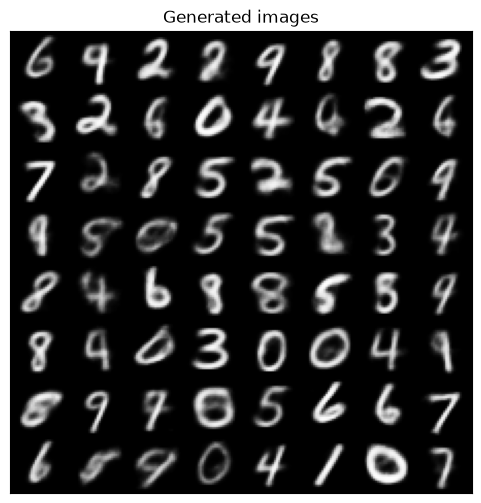

In [11]:
plot_generated_images(model)

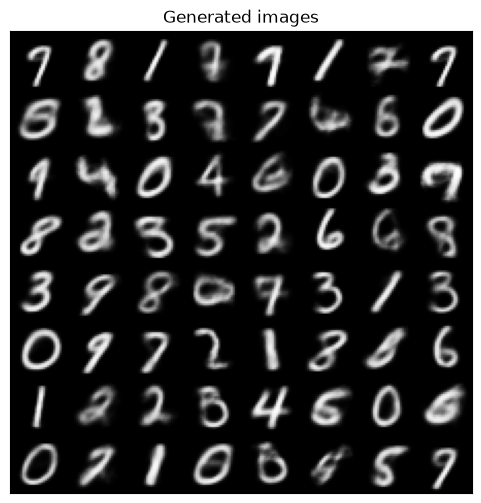

In [12]:
plot_generated_images(model)

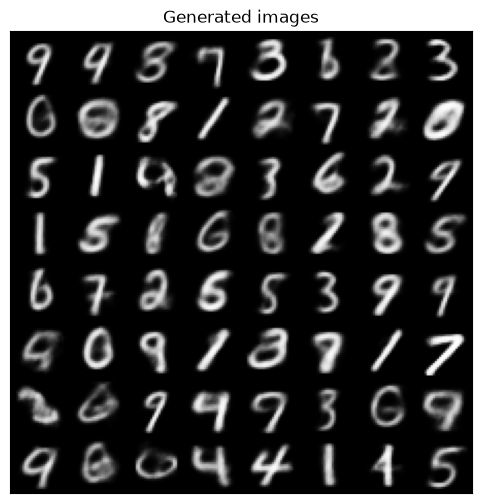

In [13]:
plot_generated_images(model)